# Choose optimal parmaters from Olsen 2006 run - February 10, 2017

Input:
- olsen2006-protein-prizes-foldchange-2-cleaned_summary_size.txt - output from summarization script
- *.err - error files from PCSF parameter sweep
- *_optimalForest.sif - optimal forest files from PCSF parameter sweeps

This uses the PCSF parameter sweeps and the output from the summarization script to produce statistics related to the connections in order to choose parameters for the PCSF noise sweeps.

Based on a notebook from Dylan.

# Load in libraries and files

In [1]:
%pylab inline

import os.path
import glob
import pandas as pd

in_dir = os.path.join('..','..','htcondor_results','results_olsen_sweep_012017')

location = os.path.join(in_dir,'olsen2006-protein-prizes-foldchange-2-cleaned_summary_size.txt')
error = os.path.join(in_dir,'*.err')
optimalForests = os.path.join(in_dir,'*_optimalForest.sif')

summary_df = pd.read_csv(location, sep = '\t')
print('Loaded summary of {} forests'.format(len(summary_df)))
summary_df.head()

Populating the interactive namespace from numpy and matplotlib
Loaded summary of 220 forests


,Forest name,Forest size,Steiner nodes,Prizes in forest,Total prizes
0,olsen2006-protein-prizes-foldchange-2-cleaned_...,24,4,20,647
1,olsen2006-protein-prizes-foldchange-2-cleaned_...,0,0,0,647
2,olsen2006-protein-prizes-foldchange-2-cleaned_...,63,8,55,647
3,olsen2006-protein-prizes-foldchange-2-cleaned_...,196,27,169,647
4,olsen2006-protein-prizes-foldchange-2-cleaned_...,0,0,0,647


## Obtain only rows with Steiner nodes > 2

In [2]:
few_steiner_df = summary_df[summary_df['Steiner nodes'] <= 2]
print "Number of forests with 2 or less steiner nodes: ", len(few_steiner_df)
print "Number of forests with more than 2 steiner nodes: ", len(summary_df) - len(few_steiner_df)

print "Number of error files: ", len(glob.glob(error))
print "Number of optimal forest files: ", len(glob.glob(optimalForests))  

print 'Keeping forests with > 2 Steiner nodes'
summary_df = summary_df[summary_df['Steiner nodes'] > 2]

Number of forests with 2 or less steiner nodes:  47
Number of forests with more than 2 steiner nodes:  173
Number of error files:  220
Number of optimal forest files:  220
Keeping forests with > 2 Steiner nodes


# Cast each column as float and divide prize nodes by forest size
Sort by prize fraction to choose the optimal forest.

In [3]:
summary_df['Prize fraction'] = summary_df.apply(lambda row: float(row['Prizes in forest']) / float(row['Forest size']), axis=1)
summary_df = summary_df.sort_values(by='Prize fraction', ascending=False)
summary_df.head(20)

,Forest name,Forest size,Steiner nodes,Prizes in forest,Total prizes,Prize fraction
18,olsen2006-protein-prizes-foldchange-2-cleaned_...,48,5,43,647,0.895833
21,olsen2006-protein-prizes-foldchange-2-cleaned_...,60,7,53,647,0.883333
61,olsen2006-protein-prizes-foldchange-2-cleaned_...,155,19,136,647,0.877419
148,olsen2006-protein-prizes-foldchange-2-cleaned_...,268,33,235,647,0.876866
2,olsen2006-protein-prizes-foldchange-2-cleaned_...,63,8,55,647,0.873016
138,olsen2006-protein-prizes-foldchange-2-cleaned_...,218,28,190,647,0.871560
17,olsen2006-protein-prizes-foldchange-2-cleaned_...,319,41,278,647,0.871473
124,olsen2006-protein-prizes-foldchange-2-cleaned_...,101,13,88,647,0.871287
196,olsen2006-protein-prizes-foldchange-2-cleaned_...,286,37,249,647,0.870629
23,olsen2006-protein-prizes-foldchange-2-cleaned_...,247,32,215,647,0.870445


C:\Program Files\Anaconda\lib\site-packages\matplotlib\collections.py:590: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if self._edgecolors == str('face'):


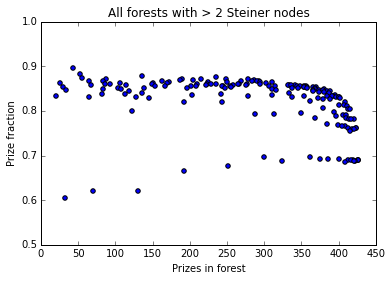

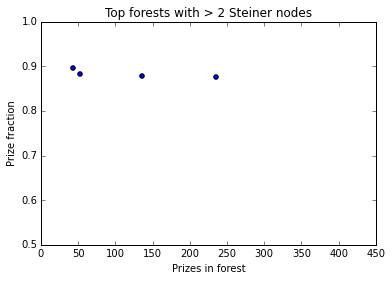

In [4]:
summary_df.plot(x='Prizes in forest', y='Prize fraction', kind='scatter');
title('All forests with > 2 Steiner nodes');
axis([0,450,0.5,1]);

top_forest_df = summary_df[summary_df['Prize fraction'] > 0.875]
top_forest_df.plot(x='Prizes in forest', y='Prize fraction', kind='scatter');
title('Top forests with > 2 Steiner nodes');
axis([0,450,0.5,1]);

## Select a single forest for the noisy edge run

With the Wolf-Yadlin prizes we choose the forest with the top prize fraction after removing forests with 0 or few Steiner nodes: "After removing the 34 small (or empty) solutions with two or fewer Steiner nodes, we selected $\beta$ = 0.55 and $\mu$ = 0.008, the solution that maximized the fraction of proteins in the Steiner forest that had prizes".

Here, we will choose the 4th ranked forest by prize fraction.  The prize fraction is similar to the maximum, but the forest size is much more similar to the Wolf-Yadlin-derived forest, which makes the comparison more fair.  Choose $\beta$ = 0.45 and $\mu$ = 0.005.

In [5]:
top_forest_df = top_forest_df[top_forest_df['Prizes in forest'] > 200]

print 'Best forest: {}'.format(top_forest_df['Forest name'].values[0])

Best forest: olsen2006-protein-prizes-foldchange-2-cleaned_beta0.45_mu0.005_omega0.1_seed12017_optimalForest.sif
